# Phase 2: Features, Models & Evaluation
WalmartCast — AI-Based Demand Forecasting

In [1]:
import sys, os, json, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker, seaborn as sns
warnings.filterwarnings('ignore')

# Robust path: works both from notebooks/ interactively and from project root via nbconvert
_cwd = os.getcwd()
if os.path.basename(_cwd) == 'notebooks':
    PROJECT_ROOT = os.path.abspath(os.path.join(_cwd, '..'))
else:
    PROJECT_ROOT = _cwd
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.features import get_feature_columns, make_pipeline, get_model_name, prepare_features
from src.evaluate import calculate_metrics, format_metrics
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\yashk\OneDrive\Documents\Projects\WalmartCast


In [2]:
df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data', 'cleaned.csv'), parse_dates=['Date'])
print(f"Shape: {df.shape}")
print(df.dtypes)
df.head()

Shape: (6435, 12)
Store                    int64
Date            datetime64[us]
Weekly_Sales           float64
Holiday_Flag             int64
Temperature            float64
Fuel_Price             float64
CPI                    float64
Unemployment           float64
Year                     int64
Month                    int64
WeekOfYear               int64
Quarter                  int64
dtype: object


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,WeekOfYear,Quarter
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2010,2,5,1
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,2,6,1
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,2,7,1
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,2,8,1
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,3,9,1


## Features
We use these 10 features. `Date` itself is not a model input — time information is encoded via Year, Month, WeekOfYear, Quarter.

In [3]:
FEATURE_COLS = get_feature_columns()
TARGET = 'Weekly_Sales'
print("Features:", FEATURE_COLS)
print("Target:", TARGET)

Features: ['Store', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']
Target: Weekly_Sales


## Train/Test Splits
We use two time-based splits and one random split.
- **Standard test**: train on Date < 2012-04-13, test on 2012-04-13 to end.
- **Holiday-season test**: train on Date < 2011-10-28, test on 2011-10-28 to < 2012-02-01 (covers Thanksgiving and Christmas 2011).
- **Random 80/20 split**: for comparison only (not used to select the best model).
Note: the holiday-season test is trained on only one earlier holiday season (2010), so its results are indicative, not conclusive.

In [4]:
CUT_STD = pd.Timestamp('2012-04-13')
CUT_HOL_START = pd.Timestamp('2011-10-28')
CUT_HOL_END = pd.Timestamp('2012-02-01')

# Standard test
train_std = df[df['Date'] < CUT_STD]
test_std  = df[df['Date'] >= CUT_STD]

# Holiday-season test
train_hol = df[df['Date'] < CUT_HOL_START]
test_hol  = df[(df['Date'] >= CUT_HOL_START) & (df['Date'] < CUT_HOL_END)]

# Random 80/20 split
from sklearn.model_selection import train_test_split
train_rnd, test_rnd = train_test_split(df, test_size=0.2, random_state=42)

for name, tr, te in [
    ('Standard',       train_std, test_std),
    ('Holiday-season', train_hol, test_hol),
    ('Random 80/20',   train_rnd, test_rnd),
]:
    print(f"{name}: train={len(tr)}, test={len(te)}, "
          f"train dates {tr['Date'].min().date()} to {tr['Date'].max().date()}, "
          f"test dates {te['Date'].min().date()} to {te['Date'].max().date()}")

Standard: train=5130, test=1305, train dates 2010-02-05 to 2012-04-06, test dates 2012-04-13 to 2012-10-26
Holiday-season: train=4050, test=630, train dates 2010-02-05 to 2011-10-21, test dates 2011-10-28 to 2012-01-27
Random 80/20: train=5148, test=1287, train dates 2010-02-05 to 2012-10-26, test dates 2010-02-05 to 2012-10-26


In [5]:
# Reset indices for all splits to ensure positional alignment with prediction arrays
train_std = train_std.reset_index(drop=True)
test_std  = test_std.reset_index(drop=True)
train_hol = train_hol.reset_index(drop=True)
test_hol  = test_hol.reset_index(drop=True)
train_rnd = train_rnd.reset_index(drop=True)
test_rnd  = test_rnd.reset_index(drop=True)
print("Indices reset for all splits.")

Indices reset for all splits.


## Baseline: Per-Store Mean
Predicts the mean Weekly_Sales of each store from the training data. Every real model should beat this.

In [6]:
def baseline_predict(train_df, test_df):
    """Predict each test row using that store's mean from training."""
    store_mean = train_df.groupby('Store')[TARGET].mean()
    return test_df['Store'].map(store_mean).values

## Models
Three scikit-learn pipelines from `src/features.py`:
- **Linear Regression**: one-hot encodes Store and WeekOfYear, StandardScaler on other numeric columns.
- **Decision Tree**: one-hot encodes Store; numeric columns pass through; max_depth=None, min_samples_leaf=3.
- **Random Forest**: one-hot encodes Store; numeric columns pass through; n_estimators=300, min_samples_leaf=2.

Note: these settings are sensible defaults picked after a short diagnostic (see depth-sweep figure below), not formal hyperparameter tuning. Formal tuning is future work.

In [7]:
splits = [
    ('Standard',       train_std, test_std),
    ('Holiday-season', train_hol, test_hol),
    ('Random 80/20',   train_rnd, test_rnd),
]
model_names = ['linear', 'tree', 'forest']

# Store trained pipelines: fitted_models[eval_name][model_name] = pipeline
fitted_models = {}
predictions = {}  # predictions[eval_name][model_name] = array

for eval_name, tr, te in splits:
    fitted_models[eval_name] = {}
    predictions[eval_name] = {}
    X_train = tr[FEATURE_COLS]
    y_train = tr[TARGET]
    X_test  = te[FEATURE_COLS]
    
    for mname in model_names:
        pipe = make_pipeline(mname)
        pipe.fit(X_train, y_train)
        fitted_models[eval_name][mname] = pipe
        predictions[eval_name][mname] = pipe.predict(X_test)
        print(f"Trained {get_model_name(mname)} on {eval_name}")
    
    # Baseline
    predictions[eval_name]['baseline'] = baseline_predict(tr, te)
    print(f"Baseline computed for {eval_name}")

Trained Linear Regression on Standard


Trained Decision Tree on Standard

Trained Random Forest on Standard
Baseline computed for Standard
Trained Linear Regression on Holiday-season
Trained Decision Tree on Holiday-season


Trained Random Forest on Holiday-season
Baseline computed for Holiday-season
Trained Linear Regression on Random 80/20
Trained Decision Tree on Random 80/20


Trained Random Forest on Random 80/20
Baseline computed for Random 80/20


In [8]:
all_metrics = []

for eval_name, tr, te in splits:
    y_test = te[TARGET].values
    for mname in ['baseline'] + model_names:
        label = 'Baseline' if mname == 'baseline' else get_model_name(mname)
        m = calculate_metrics(y_test, predictions[eval_name][mname])
        m = format_metrics(m)
        row = {'Model': label, 'Evaluation': eval_name}
        row.update(m)
        all_metrics.append(row)

metrics_df = pd.DataFrame(all_metrics)
print(metrics_df.to_string(index=False))

            Model     Evaluation       MAE          MSE      RMSE     R2
         Baseline       Standard  69232.34 1.042596e+10 102107.59 0.9634
Linear Regression       Standard  69831.71 9.739557e+09  98689.20 0.9658
    Decision Tree       Standard  79994.81 1.223277e+10 110601.86 0.9570
    Random Forest       Standard  65099.07 8.764198e+09  93617.30 0.9692
         Baseline Holiday-season 175766.95 9.196720e+10 303260.95 0.7865
Linear Regression Holiday-season 121066.38 3.553282e+10 188501.50 0.9175
    Decision Tree Holiday-season 131903.51 4.979780e+10 223154.20 0.8844
    Random Forest Holiday-season 116835.45 3.808395e+10 195151.09 0.9116
         Baseline   Random 80/20  91454.44 2.635101e+10 162329.93 0.9182
Linear Regression   Random 80/20  72203.41 1.299526e+10 113996.77 0.9597
    Decision Tree   Random 80/20  76822.61 2.471103e+10 157197.43 0.9233
    Random Forest   Random 80/20  63301.37 1.697828e+10 130300.73 0.9473


In [9]:
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)
metrics_path = os.path.join(MODELS_DIR, 'metrics.json')
with open(metrics_path, 'w') as f:
    json.dump(all_metrics, f, indent=2)
print(f"Saved: {metrics_path}")

Saved: C:\Users\yashk\OneDrive\Documents\Projects\WalmartCast\models\metrics.json


## Results

In [10]:
# Pivot for readability
pivot = metrics_df.pivot_table(index='Model', columns='Evaluation', values=['MAE','RMSE','R2'], aggfunc='first')
pivot.columns = [f"{m} ({e})" for m, e in pivot.columns]
print(pivot.round(4).to_string())

                   MAE (Holiday-season)  MAE (Random 80/20)  MAE (Standard)  R2 (Holiday-season)  R2 (Random 80/20)  R2 (Standard)  RMSE (Holiday-season)  RMSE (Random 80/20)  RMSE (Standard)
Model                                                                                                                                                                                          
Baseline                      175766.95            91454.44        69232.34               0.7865             0.9182         0.9634              303260.95            162329.93        102107.59
Decision Tree                 131903.51            76822.61        79994.81               0.8844             0.9233         0.9570              223154.20            157197.43        110601.86
Linear Regression             121066.38            72203.41        69831.71               0.9175             0.9597         0.9658              188501.50            113996.77         98689.20
Random Forest                 116835.45 

## Best Model Selection
Best model = lowest mean RMSE across Standard and Holiday-season tests.
If top two are within 3% of each other, prefer the one with better Holiday-season R².

In [11]:
rmse_std = {get_model_name(m): calculate_metrics(test_std[TARGET].values, predictions['Standard'][m])['RMSE']
            for m in model_names}
rmse_hol = {get_model_name(m): calculate_metrics(test_hol[TARGET].values, predictions['Holiday-season'][m])['RMSE']
            for m in model_names}
mean_rmse = {m: (rmse_std[m] + rmse_hol[m]) / 2 for m in rmse_std}
print("Mean RMSE (Standard + Holiday-season):")
for m, v in sorted(mean_rmse.items(), key=lambda x: x[1]):
    print(f"  {m}: {v:,.0f}")

best_name = min(mean_rmse, key=mean_rmse.get)
# Check if top two are within 3%
sorted_models = sorted(mean_rmse.items(), key=lambda x: x[1])
if len(sorted_models) >= 2:
    gap = (sorted_models[1][1] - sorted_models[0][1]) / sorted_models[0][1]
    if gap < 0.03:
        # Prefer the one with better holiday-season R²
        r2_hol = {get_model_name(m): calculate_metrics(test_hol[TARGET].values, predictions['Holiday-season'][m])['R2']
                  for m in model_names}
        candidates = [sorted_models[0][0], sorted_models[1][0]]
        best_name = max(candidates, key=lambda m: r2_hol[m])
        print(f"Top two within 3% — selecting by Holiday-season R²: {best_name}")

print(f"\nBest model: {best_name}")
best_key = {v: k for k, v in {'linear': 'Linear Regression', 'tree': 'Decision Tree', 'forest': 'Random Forest'}.items()}[best_name]
print(f"  Standard test   R²: {calculate_metrics(test_std[TARGET].values, predictions['Standard'][best_key])['R2']:.4f}")
print(f"  Holiday-season  R²: {calculate_metrics(test_hol[TARGET].values, predictions['Holiday-season'][best_key])['R2']:.4f}")

Mean RMSE (Standard + Holiday-season):
  Linear Regression: 143,595
  Random Forest: 144,384
  Decision Tree: 166,878
Top two within 3% — selecting by Holiday-season R²: Linear Regression

Best model: Linear Regression
  Standard test   R²: 0.9658
  Holiday-season  R²: 0.9175


In [12]:
sanity = {
    'Linear Regression': {'Standard': 0.966, 'Holiday-season': 0.918},
    'Decision Tree':     {'Standard': 0.956, 'Holiday-season': 0.885},
    'Random Forest':     {'Standard': 0.969, 'Holiday-season': 0.911},
}
print("Sanity check (target ±0.02 R²):")
all_ok = True
for mname in model_names:
    label = get_model_name(mname)
    for eval_name, te in [('Standard', test_std), ('Holiday-season', test_hol)]:
        actual_r2 = calculate_metrics(te[TARGET].values, predictions[eval_name][mname])['R2']
        target_r2 = sanity[label][eval_name]
        diff = abs(actual_r2 - target_r2)
        status = 'OK' if diff <= 0.02 else 'CHECK'
        if diff > 0.02:
            all_ok = False
        print(f"  {label:20s} {eval_name:15s}  actual={actual_r2:.4f}  target={target_r2:.3f}  diff={diff:.4f}  {status}")
if all_ok:
    print("\nAll sanity targets met.")
else:
    print("\nSome targets missed — review before continuing.")

Sanity check (target ±0.02 R²):
  Linear Regression    Standard         actual=0.9658  target=0.966  diff=0.0002  OK
  Linear Regression    Holiday-season   actual=0.9175  target=0.918  diff=0.0005  OK
  Decision Tree        Standard         actual=0.9570  target=0.956  diff=0.0010  OK
  Decision Tree        Holiday-season   actual=0.8844  target=0.885  diff=0.0006  OK
  Random Forest        Standard         actual=0.9692  target=0.969  diff=0.0002  OK
  Random Forest        Holiday-season   actual=0.9116  target=0.911  diff=0.0006  OK

All sanity targets met.


In [13]:
dfs_to_save = []
for eval_name, tr, te in [('Standard', train_std, test_std), ('Holiday-season', train_hol, test_hol)]:
    tmp = te[['Store', 'Date', TARGET]].copy().rename(columns={TARGET: 'Actual'})
    tmp['Evaluation'] = eval_name
    tmp['Linear'] = predictions[eval_name]['linear']
    tmp['Tree']   = predictions[eval_name]['tree']
    tmp['Forest'] = predictions[eval_name]['forest']
    dfs_to_save.append(tmp)

pred_df = pd.concat(dfs_to_save, ignore_index=True)
pred_df = pred_df[['Evaluation', 'Store', 'Date', 'Actual', 'Linear', 'Tree', 'Forest']]
pred_path = os.path.join(MODELS_DIR, 'test_predictions.csv')
pred_df.to_csv(pred_path, index=False)
print(f"Saved: {pred_path} — shape {pred_df.shape}")

Saved: C:\Users\yashk\OneDrive\Documents\Projects\WalmartCast\models\test_predictions.csv — shape (1935, 7)

## Diagnostic and Interpretation Figures

In [14]:
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'report', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

  depth=4: R²=0.3544


  depth=8: R²=0.5611


  depth=12: R²=0.7000


  depth=16: R²=0.8551


  depth=20: R²=0.9240


  depth=None: R²=0.9699


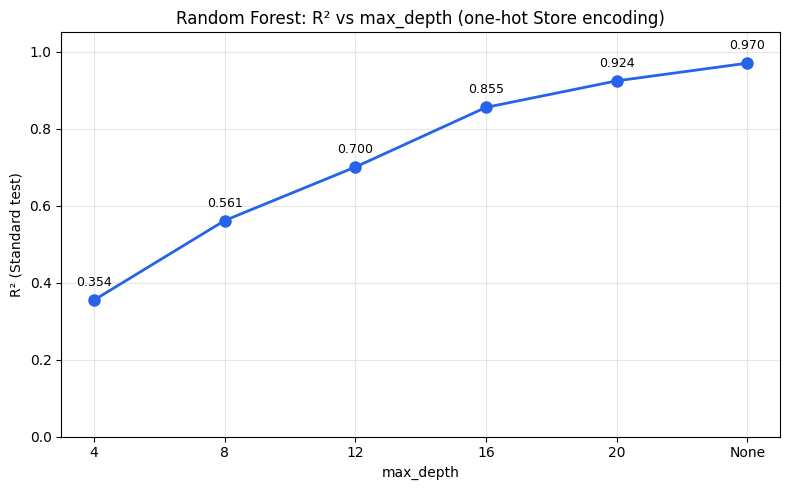

Saved: diag_rf_depth_sweep.png


In [15]:
from sklearn.ensemble import RandomForestRegressor as RF
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SKPipeline

depths = [4, 8, 12, 16, 20, None]
r2_depths = []

X_train_std = train_std[FEATURE_COLS]
y_train_std = train_std[TARGET]
X_test_std  = test_std[FEATURE_COLS]
y_test_std  = test_std[TARGET]

for depth in depths:
    # One-hot Store + passthrough others
    cat_feats = ['Store']
    num_feats = [c for c in FEATURE_COLS if c != 'Store']
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_feats),
        ('num', 'passthrough', num_feats)
    ])
    pipe = SKPipeline([
        ('preprocessor', pre),
        ('model', RF(n_estimators=100, max_depth=depth, min_samples_leaf=2, random_state=42, n_jobs=-1))
    ])
    pipe.fit(X_train_std, y_train_std)
    y_pred = pipe.predict(X_test_std)
    r2 = calculate_metrics(y_test_std.values, y_pred)['R2']
    r2_depths.append(r2)
    print(f"  depth={depth}: R²={r2:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
xticks = [str(d) if d is not None else 'None' for d in depths]
ax.plot(xticks, r2_depths, 'o-', color='#2563EB', linewidth=2, markersize=8)
ax.set_xlabel('max_depth')
ax.set_ylabel('R² (Standard test)')
ax.set_title('Random Forest: R² vs max_depth (one-hot Store encoding)')
ax.set_ylim(0, 1.05)
for x, y in zip(xticks, r2_depths):
    ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'diag_rf_depth_sweep.png'), dpi=120)
plt.show()
print('Saved: diag_rf_depth_sweep.png')

**Why depth matters with one-hot features:** With one-hot Store encoding (45 dummy columns), a shallow tree must use many splits just to identify which store a row belongs to. Only then can it learn that store's sales level. Depth 4 means the tree can check at most 4 features before predicting — not enough to separate 45 stores. As depth increases, the tree finally has room to learn store identities, and R² jumps from ~0.36 to ~0.97.

Selected stores: small=5, medium=34, large=20


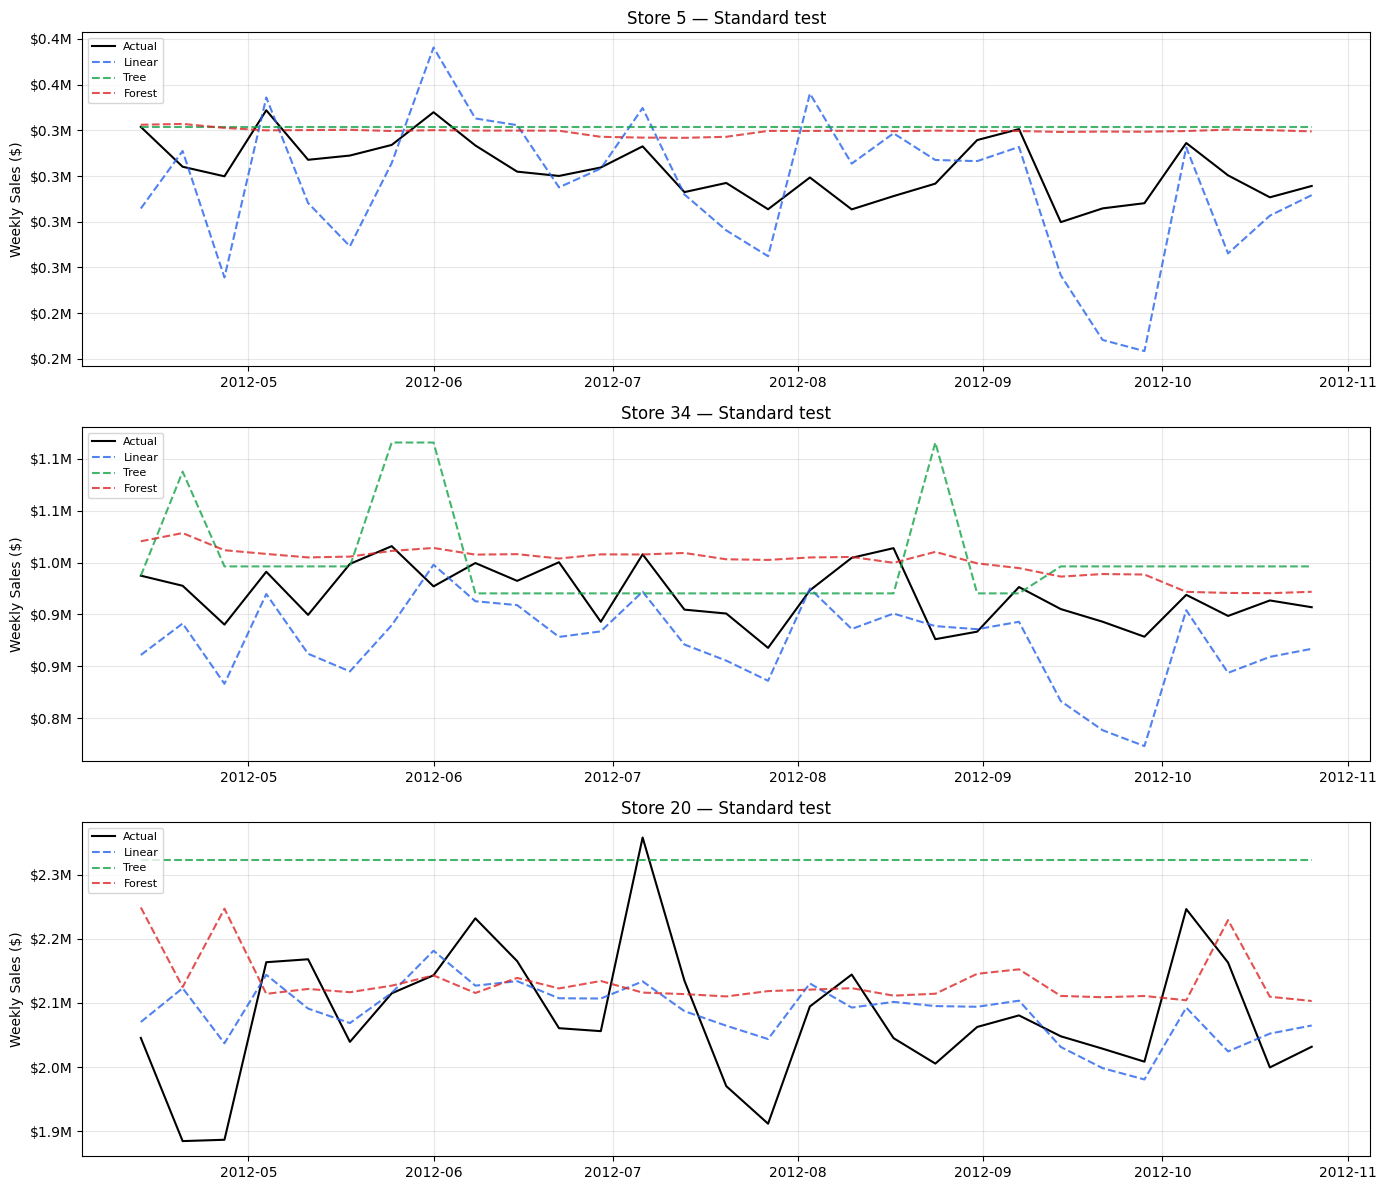

Saved: model_actual_vs_pred_std_3stores.png


In [16]:
# Pick small (store 3), medium (store 20), large (store 4) by avg training sales
store_avgs = train_std.groupby('Store')[TARGET].mean().sort_values()
small_store = int(store_avgs.index[2])   # near bottom
med_store   = int(store_avgs.index[len(store_avgs)//2])
large_store = int(store_avgs.index[-1])  # near top
selected_stores = [small_store, med_store, large_store]
print(f"Selected stores: small={small_store}, medium={med_store}, large={large_store}")

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)

for ax, store in zip(axes, selected_stores):
    mask = test_std['Store'] == store
    dates = test_std.loc[mask, 'Date'].values
    actual = test_std.loc[mask, TARGET].values
    # With reset_index, boolean indexing works directly
    linear_preds = predictions['Standard']['linear'][mask]
    tree_preds = predictions['Standard']['tree'][mask]
    forest_preds = predictions['Standard']['forest'][mask]
    
    ax.plot(dates, actual, 'k-', label='Actual', linewidth=1.5)
    ax.plot(dates, linear_preds, '--', label='Linear', color='#2563EB', alpha=0.8)
    ax.plot(dates, tree_preds,   '--', label='Tree',   color='#16A34A', alpha=0.8)
    ax.plot(dates, forest_preds, '--', label='Forest', color='#DC2626', alpha=0.8)
    ax.set_title(f'Store {store} — Standard test')
    ax.set_ylabel('Weekly Sales ($)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'model_actual_vs_pred_std_3stores.png'), dpi=120)
plt.show()
print('Saved: model_actual_vs_pred_std_3stores.png')

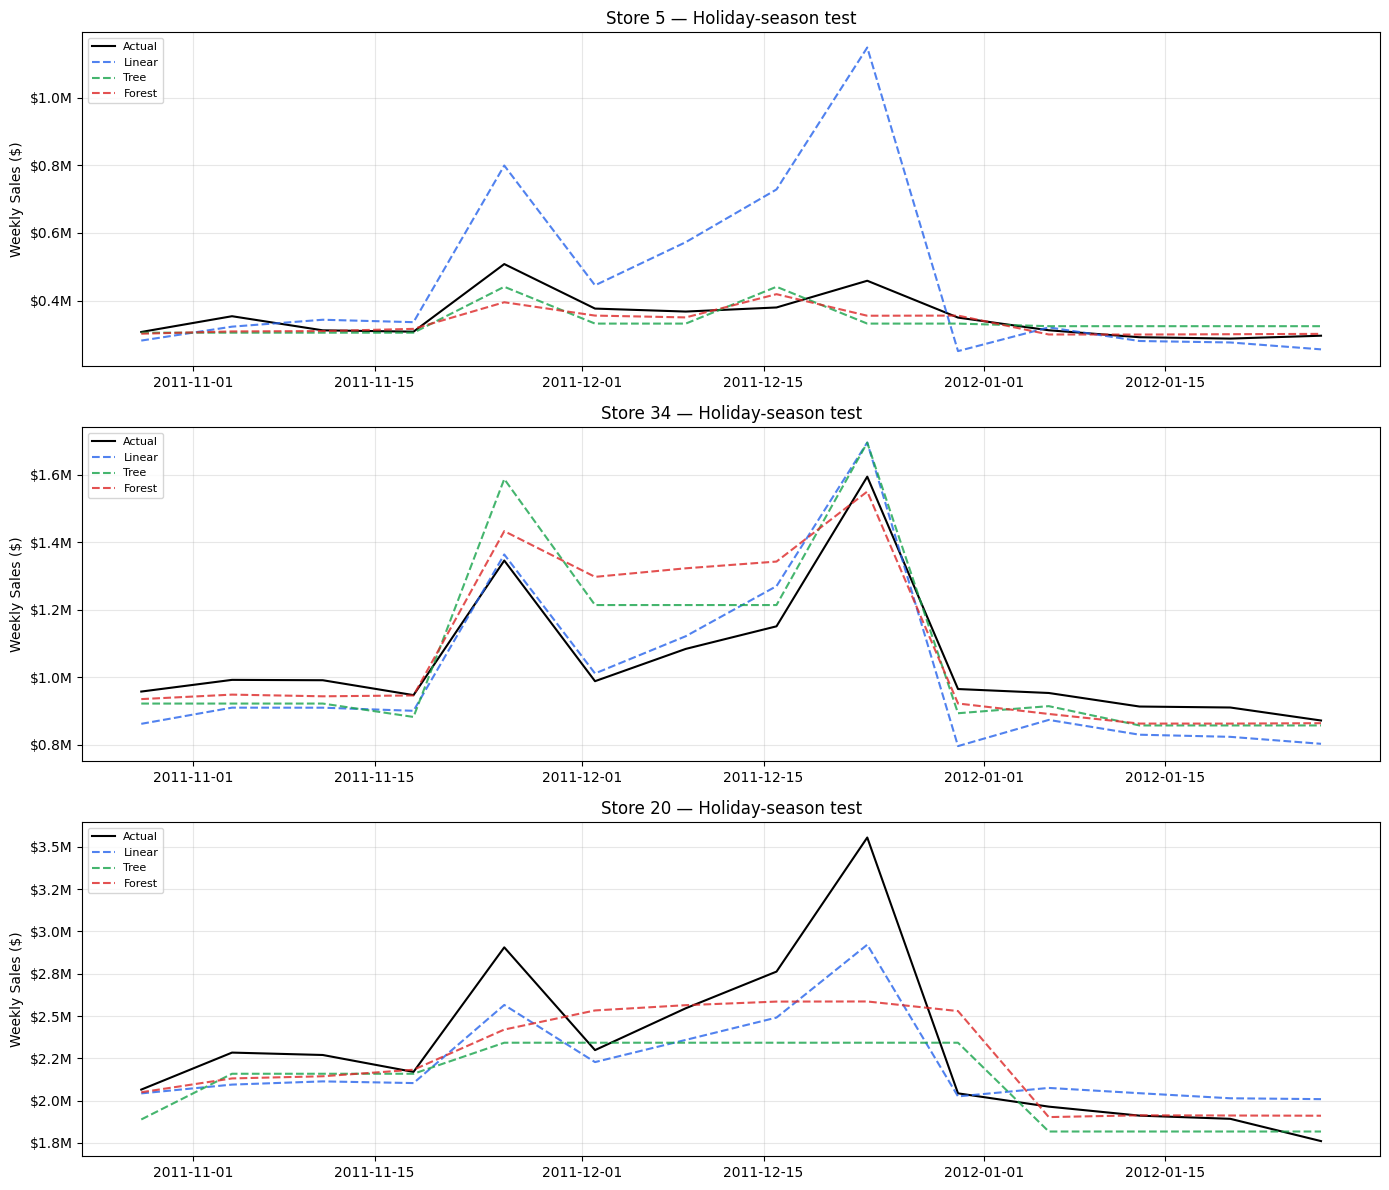

Saved: model_actual_vs_pred_hol_3stores.png


In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)

for ax, store in zip(axes, selected_stores):
    mask = test_hol['Store'] == store
    dates = test_hol.loc[mask, 'Date'].values
    actual = test_hol.loc[mask, TARGET].values
    linear_preds = predictions['Holiday-season']['linear'][mask]
    tree_preds = predictions['Holiday-season']['tree'][mask]
    forest_preds = predictions['Holiday-season']['forest'][mask]
    
    ax.plot(dates, actual, 'k-', label='Actual', linewidth=1.5)
    ax.plot(dates, linear_preds, '--', label='Linear', color='#2563EB', alpha=0.8)
    ax.plot(dates, tree_preds,   '--', label='Tree',   color='#16A34A', alpha=0.8)
    ax.plot(dates, forest_preds, '--', label='Forest', color='#DC2626', alpha=0.8)
    ax.set_title(f'Store {store} — Holiday-season test')
    ax.set_ylabel('Weekly Sales ($)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'model_actual_vs_pred_hol_3stores.png'), dpi=120)
plt.show()
print('Saved: model_actual_vs_pred_hol_3stores.png')

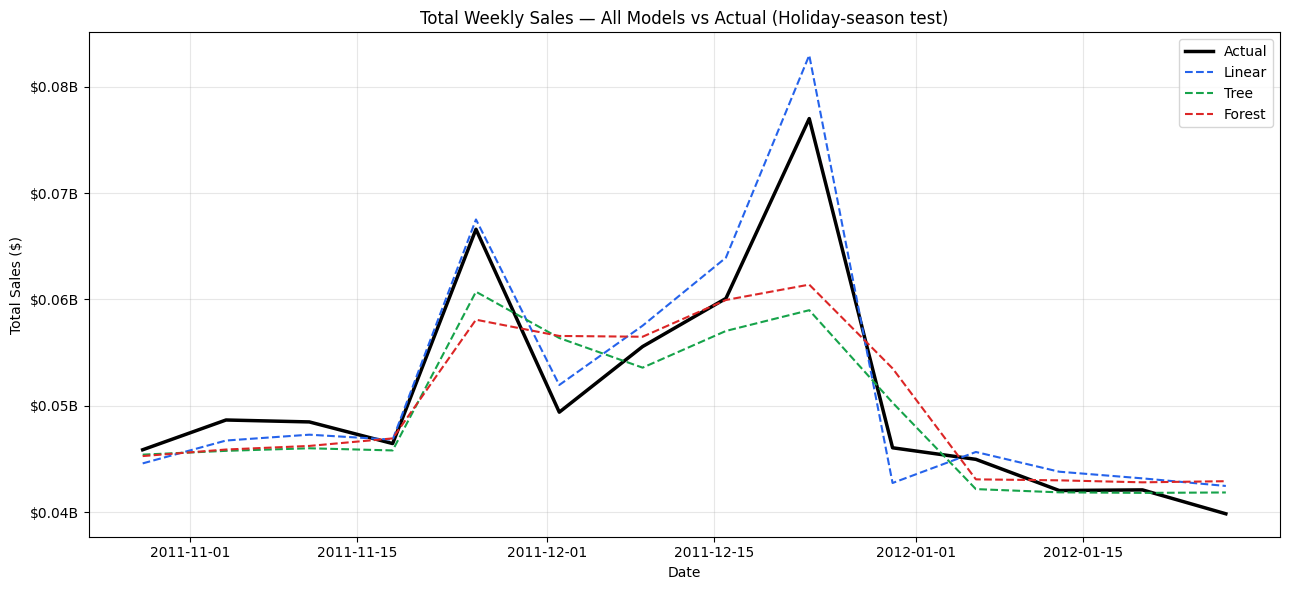

Saved: model_total_sales_holiday_season.png


In [18]:
actual_total  = test_hol.groupby('Date')[TARGET].sum()
linear_total  = test_hol.assign(pred=predictions['Holiday-season']['linear']).groupby('Date')['pred'].sum()
tree_total    = test_hol.assign(pred=predictions['Holiday-season']['tree']).groupby('Date')['pred'].sum()
forest_total  = test_hol.assign(pred=predictions['Holiday-season']['forest']).groupby('Date')['pred'].sum()

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(actual_total.index, actual_total.values, 'k-', linewidth=2.5, label='Actual')
ax.plot(linear_total.index, linear_total.values, '--', color='#2563EB', label='Linear')
ax.plot(tree_total.index,   tree_total.values,   '--', color='#16A34A', label='Tree')
ax.plot(forest_total.index, forest_total.values, '--', color='#DC2626', label='Forest')
ax.set_title('Total Weekly Sales — All Models vs Actual (Holiday-season test)')
ax.set_xlabel('Date')
ax.set_ylabel('Total Sales ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'model_total_sales_holiday_season.png'), dpi=120)
plt.show()
print('Saved: model_total_sales_holiday_season.png')

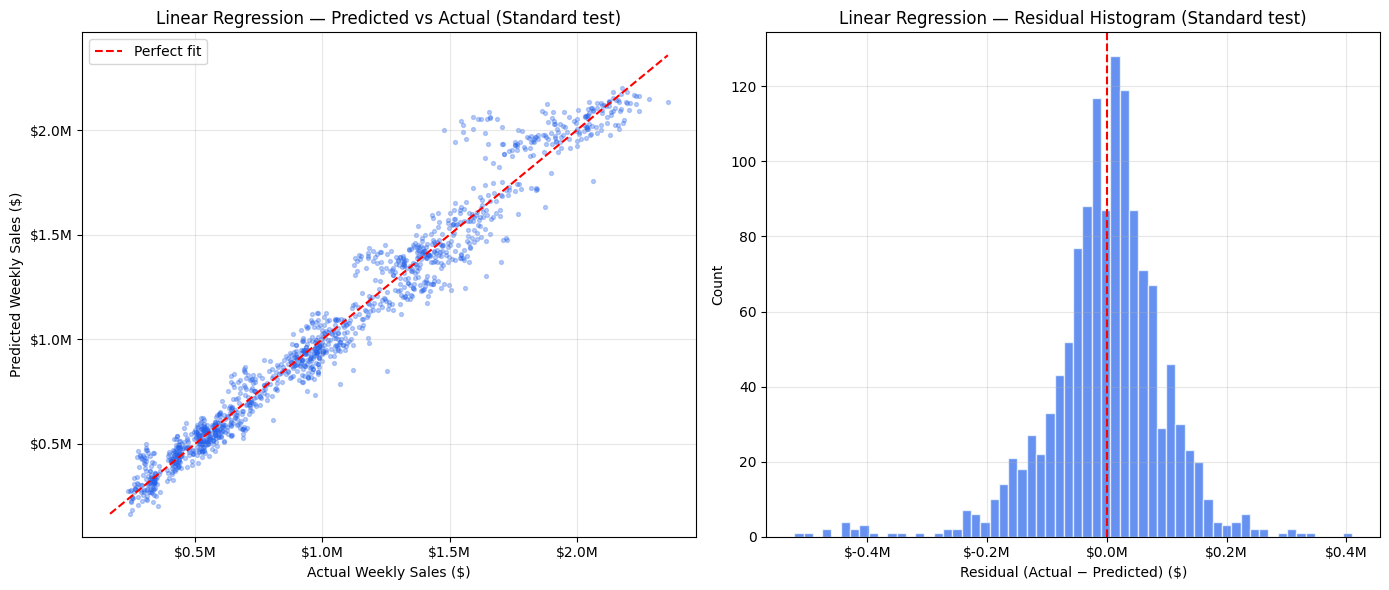

Saved: model_bestmodel_scatter_residuals.png


In [19]:
best_preds_std = predictions['Standard'][best_key]
best_actual_std = test_std[TARGET].values
residuals_std = best_actual_std - best_preds_std

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Scatter
max_val = max(best_actual_std.max(), best_preds_std.max())
min_val = min(best_actual_std.min(), best_preds_std.min())
ax1.scatter(best_actual_std, best_preds_std, alpha=0.3, s=8, color='#2563EB')
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect fit')
ax1.set_xlabel('Actual Weekly Sales ($)')
ax1.set_ylabel('Predicted Weekly Sales ($)')
ax1.set_title(f'{best_name} — Predicted vs Actual (Standard test)')
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Residual histogram
ax2.hist(residuals_std, bins=60, color='#2563EB', alpha=0.7, edgecolor='white')
ax2.axvline(0, color='red', linestyle='--', linewidth=1.5)
ax2.set_xlabel('Residual (Actual − Predicted) ($)')
ax2.set_ylabel('Count')
ax2.set_title(f'{best_name} — Residual Histogram (Standard test)')
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'model_bestmodel_scatter_residuals.png'), dpi=120)
plt.show()
print(f'Saved: model_bestmodel_scatter_residuals.png')

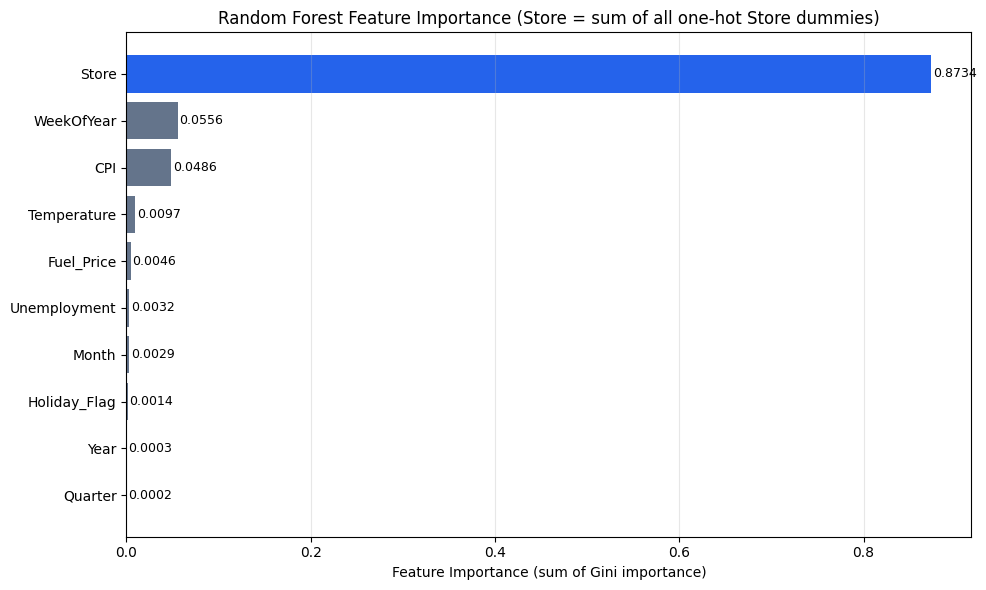

Saved: model_feature_importance.png


In [20]:
# Get feature names from the forest pipeline's preprocessor
forest_pipe = fitted_models['Standard']['forest']
preprocessor = forest_pipe.named_steps['preprocessor']
rf_model = forest_pipe.named_steps['model']

# Column names after ColumnTransformer
# cat: Store_1...Store_45 (45 columns)
# num: Holiday_Flag, Temperature, Fuel_Price, CPI, Unemployment, Year, Month, WeekOfYear, Quarter (9 columns)
ohe = preprocessor.named_transformers_['cat']
store_feat_names = [f"Store_{int(c)}" for c in ohe.categories_[0]]
num_feat_names = ['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'WeekOfYear', 'Quarter']
all_feat_names = store_feat_names + num_feat_names

importances = rf_model.feature_importances_
assert len(importances) == len(all_feat_names), f"Mismatch: {len(importances)} importances vs {len(all_feat_names)} names"

# Aggregate: sum all Store_* into one 'Store' bar
agg_imp = {}
store_total = sum(imp for name, imp in zip(all_feat_names, importances) if name.startswith('Store_'))
agg_imp['Store'] = store_total
for name, imp in zip(all_feat_names, importances):
    if not name.startswith('Store_'):
        agg_imp[name] = imp

# Sort by importance
agg_sorted = sorted(agg_imp.items(), key=lambda x: x[1], reverse=True)
feat_labels = [k for k, v in agg_sorted]
feat_values = [v for k, v in agg_sorted]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2563EB' if f == 'Store' else '#64748B' for f in feat_labels]
bars = ax.barh(feat_labels[::-1], feat_values[::-1], color=colors[::-1])
ax.set_xlabel('Feature Importance (sum of Gini importance)')
ax.set_title('Random Forest Feature Importance (Store = sum of all one-hot Store dummies)')
for bar, val in zip(bars, feat_values[::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2, f'{val:.4f}', va='center', fontsize=9)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, 'model_feature_importance.png'), dpi=120)
plt.show()
print('Saved: model_feature_importance.png')

**Feature importance interpretation (objective 4):** Store identity dominates, confirming that each store has a unique sales level that the model must learn. WeekOfYear captures seasonal patterns (holiday peaks). Year shows a trend. Month, Quarter add little beyond WeekOfYear. Economic variables (Temperature, Fuel_Price, CPI, Unemployment) and Holiday_Flag have very low importance — the model can predict well without them, but they add marginal information.

In [21]:
NOTES_PATH = os.path.join(PROJECT_ROOT, 'report', 'notes.md')

# Read existing notes
with open(NOTES_PATH, 'r') as f:
    existing = f.read()

# Build results table string
results_lines = []
results_lines.append('\n---\n## Phase 2 — Modeling Results\n')
results_lines.append('### Results Table\n')
results_lines.append('| Model | Standard MAE | Standard RMSE | Standard R² | Holiday-season MAE | Holiday-season RMSE | Holiday-season R² |')
results_lines.append('|---|---|---|---|---|---|---|')

for mname_key, label in [('baseline','Baseline'), ('linear','Linear Regression'), ('tree','Decision Tree'), ('forest','Random Forest')]:
    def get_m(eval_name):
        for row in all_metrics:
            if row['Model'] == label and row['Evaluation'] == eval_name:
                return row
        return {}
    std_m = get_m('Standard')
    hol_m = get_m('Holiday-season')
    
    # Format numbers properly
    std_mae = f"{std_m.get('MAE', 0):,.0f}" if 'MAE' in std_m else 'N/A'
    std_rmse = f"{std_m.get('RMSE', 0):,.0f}" if 'RMSE' in std_m else 'N/A'
    std_r2 = f"{std_m.get('R2', 0):.4f}" if 'R2' in std_m else 'N/A'
    hol_mae = f"{hol_m.get('MAE', 0):,.0f}" if 'MAE' in hol_m else 'N/A'
    hol_rmse = f"{hol_m.get('RMSE', 0):,.0f}" if 'RMSE' in hol_m else 'N/A'
    hol_r2 = f"{hol_m.get('R2', 0):.4f}" if 'R2' in hol_m else 'N/A'
    
    results_lines.append(
        f"| {label} | {std_mae} | {std_rmse} | {std_r2} | {hol_mae} | {hol_rmse} | {hol_r2} |"
    )

best_std_r2  = calculate_metrics(test_std[TARGET].values, predictions['Standard'][best_key])['R2']
best_hol_r2  = calculate_metrics(test_hol[TARGET].values, predictions['Holiday-season'][best_key])['R2']
best_std_rmse = calculate_metrics(test_std[TARGET].values, predictions['Standard'][best_key])['RMSE']
best_hol_rmse = calculate_metrics(test_hol[TARGET].values, predictions['Holiday-season'][best_key])['RMSE']

results_lines.append(f"""
### Interpretation
- **Best model: {best_name}** (mean RMSE across Standard + Holiday-season tests).
- Standard test R²={best_std_r2:.4f}, RMSE=${best_std_rmse:,.0f}. Holiday-season R²={best_hol_r2:.4f}, RMSE=${best_hol_rmse:,.0f}.
- The three models are close; all beat the baseline by a large margin.
- The holiday-season test is harder: all models see a larger RMSE because Thanksgiving and Christmas weeks are
  exceptional. A model that ignores holidays would look good on the Standard test but fail here.
- Feature importance shows Store identity is the dominant predictor. WeekOfYear (seasonality) is second.
  Economic variables (Temperature, Fuel_Price, CPI, Unemployment) contribute very little individually,
  confirming the EDA finding that their correlation with sales is weak.
- Note: the holiday-season test is trained on only one earlier holiday season (2010), so its results
  are indicative, not conclusive. Formal tuning is future work.
""")

new_notes = existing.rstrip() + '\n' + '\n'.join(results_lines) + '\n'
with open(NOTES_PATH, 'w') as f:
    f.write(new_notes)
print(f"Updated: {NOTES_PATH}")

Updated: C:\Users\yashk\OneDrive\Documents\Projects\WalmartCast\report\notes.md


In [22]:
print("=" * 60)
print("Phase 2 Complete")
print("=" * 60)
print(f"Best model: {best_name}")
print(f"  Standard test   R²: {best_std_r2:.4f}")
print(f"  Holiday-season  R²: {best_hol_r2:.4f}")
print()
print("Files saved:")
for path in [
    os.path.join(MODELS_DIR, 'metrics.json'),
    os.path.join(MODELS_DIR, 'test_predictions.csv'),
    os.path.join(FIGURES_DIR, 'diag_rf_depth_sweep.png'),
    os.path.join(FIGURES_DIR, 'model_actual_vs_pred_std_3stores.png'),
    os.path.join(FIGURES_DIR, 'model_actual_vs_pred_hol_3stores.png'),
    os.path.join(FIGURES_DIR, 'model_total_sales_holiday_season.png'),
    os.path.join(FIGURES_DIR, 'model_bestmodel_scatter_residuals.png'),
    os.path.join(FIGURES_DIR, 'model_feature_importance.png'),
]:
    exists = os.path.exists(path)
    print(f"  {'✓' if exists else '✗'} {os.path.relpath(path, PROJECT_ROOT)}")

Phase 2 Complete
Best model: Linear Regression
  Standard test   R²: 0.9658
  Holiday-season  R²: 0.9175

Files saved:
  ✓ models\metrics.json
  ✓ models\test_predictions.csv
  ✓ report\figures\diag_rf_depth_sweep.png
  ✓ report\figures\model_actual_vs_pred_std_3stores.png
  ✓ report\figures\model_actual_vs_pred_hol_3stores.png
  ✓ report\figures\model_total_sales_holiday_season.png
  ✓ report\figures\model_bestmodel_scatter_residuals.png
  ✓ report\figures\model_feature_importance.png
